# Tâche A3 — 1.2 Statistiques descriptives

**Projet d'économétrie appliquée** · Consommation d'énergie et rénovation thermique · Responsable : Membre 1

**Entrée** : `data/processed/logements_propres.csv` (1 998 logements, produit par A1).

**Contenu (énoncé §1.2)**
1. Tableau récapitulatif des variables quantitatives : moyenne $\bar X$, médiane, écart-type $s_X$, minimum, maximum, quartiles.
2. Asymétrie (*skewness*) et aplatissement (*kurtosis*) de `Conso_kWh` et de `log(Conso_kWh)`.
3. Histogrammes de `Conso_kWh` et de son logarithme ; boîtes à moustaches selon le mode de chauffage et le type de logement.
4. Quelles variables pourraient nécessiter une transformation logarithmique ?

**Définitions utilisées** (moments centrés d'ordre $k$ : $m_k=\frac1N\sum_i (x_i-\bar x)^k$)

$$\text{Skewness}=g_1=\frac{m_3}{m_2^{3/2}},\qquad \text{Kurtosis}=g_2=\frac{m_4}{m_2^{2}}$$

Pour une loi normale, $g_1=0$ et $g_2=3$ (on donne aussi le *kurtosis en excès* $g_2-3$). L'écart-type $s_X$ utilise le diviseur $N-1$ (convention `pandas`), les quartiles sont obtenus par interpolation linéaire.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PROC, FIG, TAB = ROOT / "data" / "processed", ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
for p in (FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PROC / "logements_propres.csv")
print("Observations :", len(df))
df["log_Conso"] = np.log(df["Conso_kWh"])

Observations : 1998


## 1. Tableau récapitulatif des variables quantitatives

Les variables **quantitatives** sont celles qui ont une échelle numérique ; les indicatrices 0/1 (`Maison`, `Proprietaire`, équipements, `Renovation`, `Cheque_renovation`) et le mode de chauffage sont qualitatifs et traités plus bas (fréquences). `Teletravail_jours`, `Nb_occupants` et `Nb_ecrans` sont des comptages, conservés ici car ils entrent comme variables numériques dans les modèles.

In [2]:
quanti = ["Conso_kWh", "Surface_m2", "Nb_occupants", "Annee_construction", "DJU", "Revenu_kEUR",
          "Age_referent", "Teletravail_jours", "Nb_ecrans", "Artisans_RGE"]

def resume(x):
    return pd.Series({
        "N": x.count(), "Moyenne": x.mean(), "Médiane": x.median(), "Écart-type": x.std(ddof=1),
        "Min": x.min(), "Q1": x.quantile(.25), "Q3": x.quantile(.75), "Max": x.max(),
        "Asymétrie": stats.skew(x), "Kurtosis": stats.kurtosis(x, fisher=False),
    })

tableau = df[quanti].apply(resume).T
tableau["N"] = tableau["N"].astype(int)
tableau.round(2).to_csv(TAB / "a3_stats_descriptives.csv")
tableau.round(2)

,N,Moyenne,Médiane,Écart-type,Min,Q1,Q3,Max,Asymétrie,Kurtosis
Conso_kWh,1998,15470.24,13440.5,8735.19,2901.0,9400.50,19143.75,70298.0,1.70,7.41
Surface_m2,1998,94.15,89.0,39.98,15.0,64.00,116.75,288.0,0.88,4.11
Nb_occupants,1998,3.10,3.0,1.32,1.0,2.00,4.00,7.0,0.37,2.84
Annee_construction,1998,1968.91,1976.0,36.31,1880.0,1950.00,1997.00,2023.0,-0.71,2.66
DJU,1998,2403.80,2399.0,345.65,1300.0,2176.75,2631.00,3600.0,0.07,3.14
Revenu_kEUR,1998,42.42,37.4,21.33,9.0,27.62,52.10,211.1,1.78,8.78
Age_referent,1998,51.91,52.0,14.59,22.0,41.00,62.00,90.0,0.08,2.60
Teletravail_jours,1998,0.83,0.0,1.52,0.0,0.00,1.00,5.0,1.68,4.40
Nb_ecrans,1998,3.18,3.0,2.00,0.0,2.00,4.00,12.0,0.69,3.43
Artisans_RGE,1998,7.44,7.4,2.49,0.5,5.80,9.10,15.9,-0.00,3.06


### Variables qualitatives : fréquences

In [3]:
print("Mode de chauffage :")
print(pd.concat([df["Chauffage"].value_counts(), df["Chauffage"].value_counts(normalize=True).round(3)], axis=1,
                keys=["effectif", "part"]).to_string())
binaires = ["Maison", "Proprietaire", "Renovation", "Cheque_renovation", "Piscine", "Voiture_electrique", "Climatisation",
            "Seche_linge", "Congelateur", "Ballon_electrique", "Panneaux_solaires", "Thermostat_connecte",
            "Lave_vaisselle", "Animal_compagnie", "Jardin", "Velo", "Abonnement_streaming"]
freq = (df[binaires].mean() * 100).round(1).rename("% de ménages (=1)").to_frame()
freq.to_csv(TAB / "a3_frequences_binaires.csv")
freq.T

Mode de chauffage :
            effectif   part
Chauffage                  
Gaz              801  0.401
Electrique       796  0.398
PAC              219  0.110
Bois             130  0.065
Fioul             52  0.026


,Maison,Proprietaire,Renovation,Cheque_renovation,Piscine,Voiture_electrique,Climatisation,Seche_linge,Congelateur,Ballon_electrique,Panneaux_solaires,Thermostat_connecte,Lave_vaisselle,Animal_compagnie,Jardin,Velo,Abonnement_streaming
% de ménages (=1),56.2,55.0,36.2,24.6,5.7,3.2,17.0,32.1,47.7,44.4,4.3,10.3,60.0,42.8,56.5,39.7,68.4


**Lecture rapide.** La consommation moyenne (15 470 kWh/an) dépasse nettement la médiane (13 441 kWh/an) : signe d'une **distribution étalée vers la droite** (quelques très gros consommateurs, jusqu'à 70 298 kWh). Même constat pour le revenu (moyenne 42,4 k€ contre médiane 37,4 k€). À l'inverse, les DJU, l'âge du référent et les artisans RGE ont une moyenne proche de la médiane et une asymétrie quasi nulle (distributions symétriques). Le télétravail est très concentré en 0 : 72 % des ménages ne télétravaillent pas (1 436 sur 1 998).

## 2. Asymétrie et aplatissement : `Conso_kWh` et `log(Conso_kWh)`

In [4]:
rows = []
for nom, x in [("Conso_kWh", df["Conso_kWh"]), ("log(Conso_kWh)", df["log_Conso"])]:
    jb = stats.jarque_bera(x)
    rows.append({"variable": nom, "Asymétrie": stats.skew(x), "Kurtosis": stats.kurtosis(x, fisher=False),
                 "Kurtosis en excès": stats.kurtosis(x, fisher=True), "Jarque-Bera": jb.statistic, "p-valeur JB": jb.pvalue})
sk = pd.DataFrame(rows).set_index("variable")
sk.round(3).to_csv(TAB / "a3_skew_kurt_conso.csv")
sk.round(3)

,Asymétrie,Kurtosis,Kurtosis en excès,Jarque-Bera,p-valeur JB
variable,,,,,
Conso_kWh,1.699,7.413,4.413,2582.985,0.000
log(Conso_kWh),0.090,2.814,-0.186,5.576,0.062


**Interprétation.**

- `Conso_kWh` : asymétrie ≈ **1,70** (forte asymétrie à droite) et kurtosis ≈ **7,41** (queues très épaisses, bien au-dessus de 3). Le test de Jarque-Bera (hypothèse nulle : asymétrie 0 et kurtosis 3) est **rejeté** de manière écrasante (statistique ≈ 2 583, p-valeur ≈ 0) : la consommation n'est pas normale.
- `log(Conso_kWh)` : asymétrie ≈ **0,09** et kurtosis ≈ **2,81** : très proche de la loi normale. Jarque-Bera = 5,58, p-valeur ≈ **0,062** : on **ne rejette pas** la normalité au seuil de 5 %.

Le passage au logarithme corrige donc presque entièrement l'asymétrie et l'épaisseur des queues. C'est conforme au cours (« Advantages of using logs » : résidus plus proches de la normalité, hétéroscédasticité réduite, coefficients interprétables en pourcentages ou en élasticités). Attention : ce test porte sur la **variable**, pas sur les résidus d'un modèle. La normalité des résidus sera vérifiée après estimation.

## 3. Histogrammes de `Conso_kWh` et de `log(Conso_kWh)`

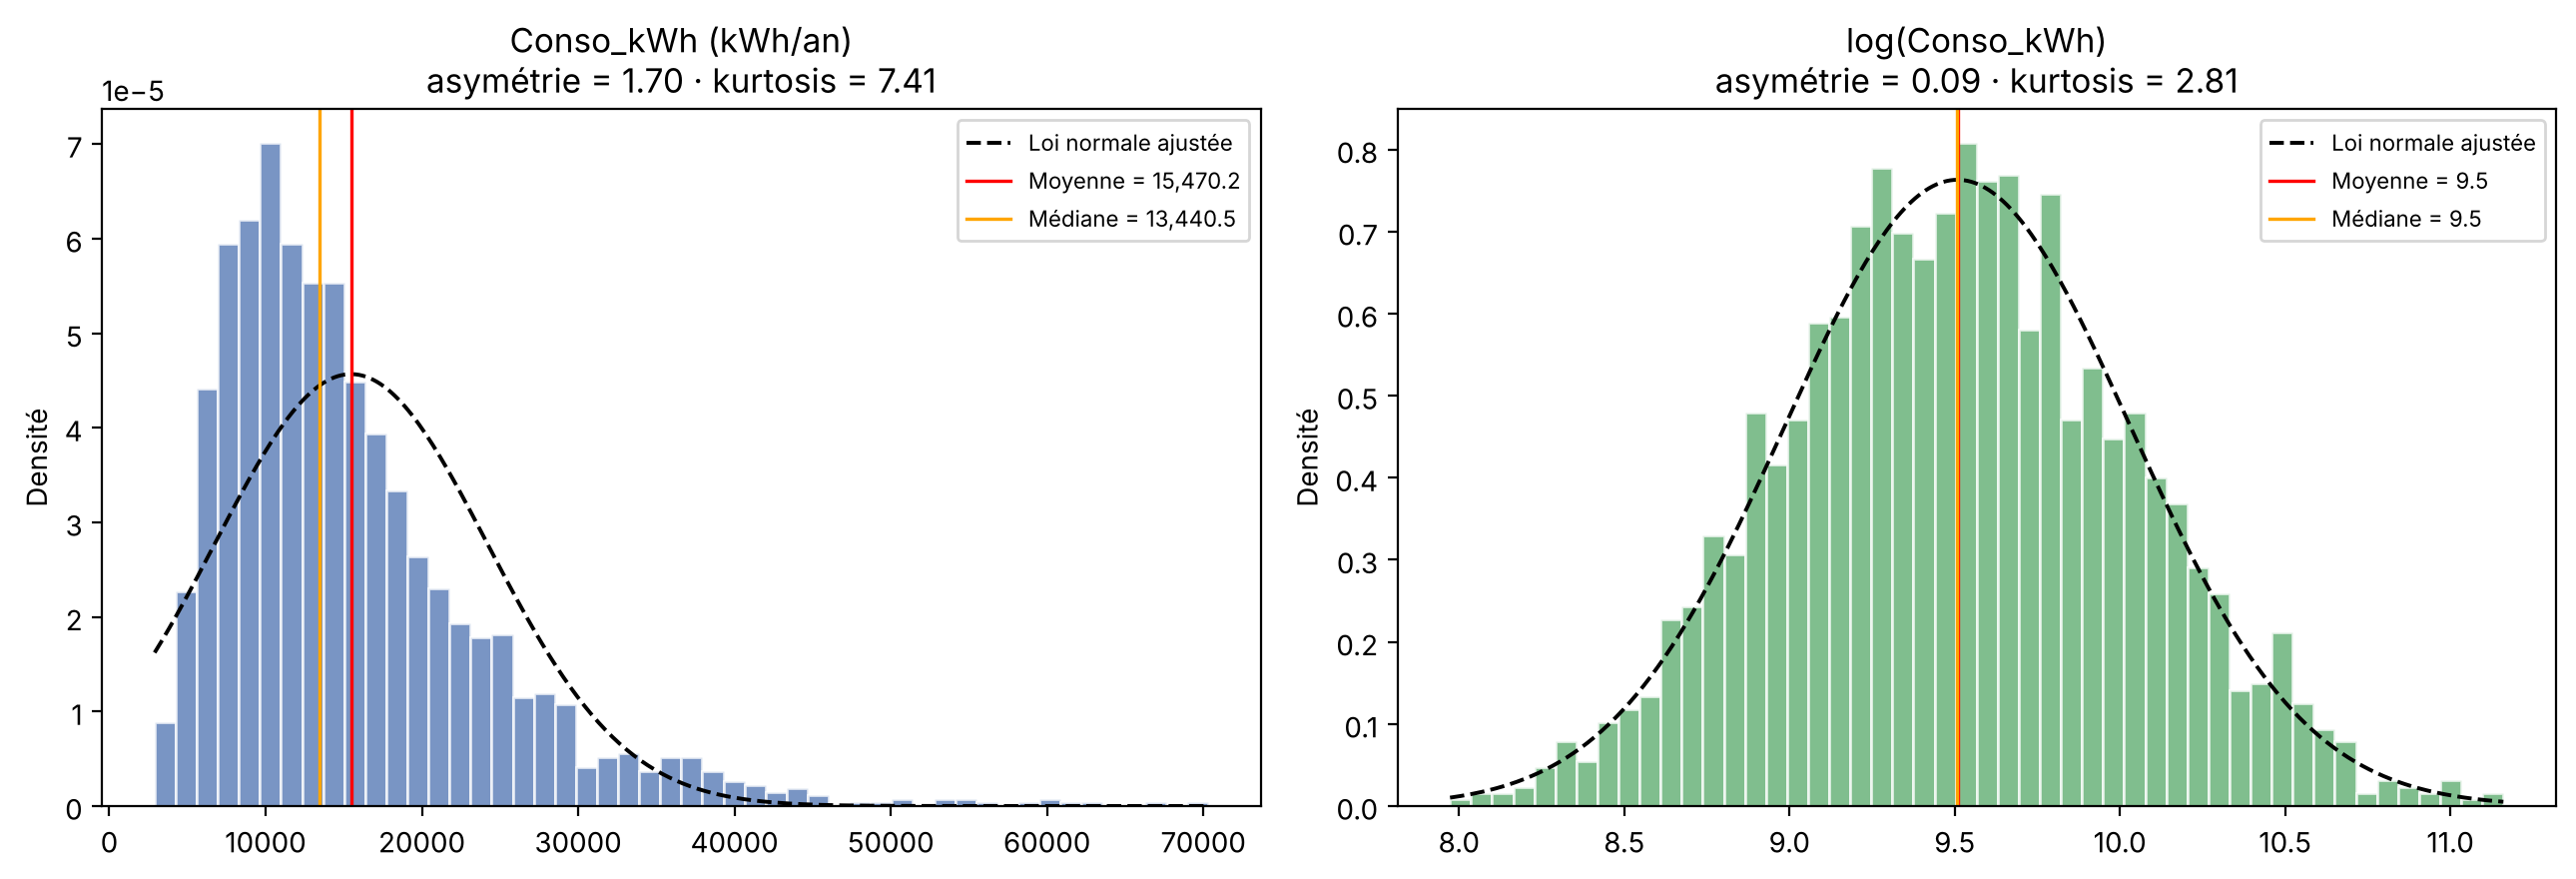

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, x, titre, couleur in [(ax[0], df["Conso_kWh"], "Conso_kWh (kWh/an)", "#4C72B0"),
                             (ax[1], df["log_Conso"], "log(Conso_kWh)", "#55A868")]:
    a.hist(x, bins=50, density=True, color=couleur, alpha=.75, edgecolor="white")
    grille = np.linspace(x.min(), x.max(), 300)
    a.plot(grille, stats.norm.pdf(grille, x.mean(), x.std()), "k--", lw=1.4, label="Loi normale ajustée")
    a.axvline(x.mean(), color="red", lw=1.2, label=f"Moyenne = {x.mean():,.1f}")
    a.axvline(x.median(), color="orange", lw=1.2, label=f"Médiane = {x.median():,.1f}")
    a.set_title(f"{titre}\nasymétrie = {stats.skew(x):.2f} · kurtosis = {stats.kurtosis(x, fisher=False):.2f}")
    a.set_ylabel("Densité"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "a3_hist_conso_log.png", dpi=150); plt.show()

## 4. Boîtes à moustaches : mode de chauffage et type de logement

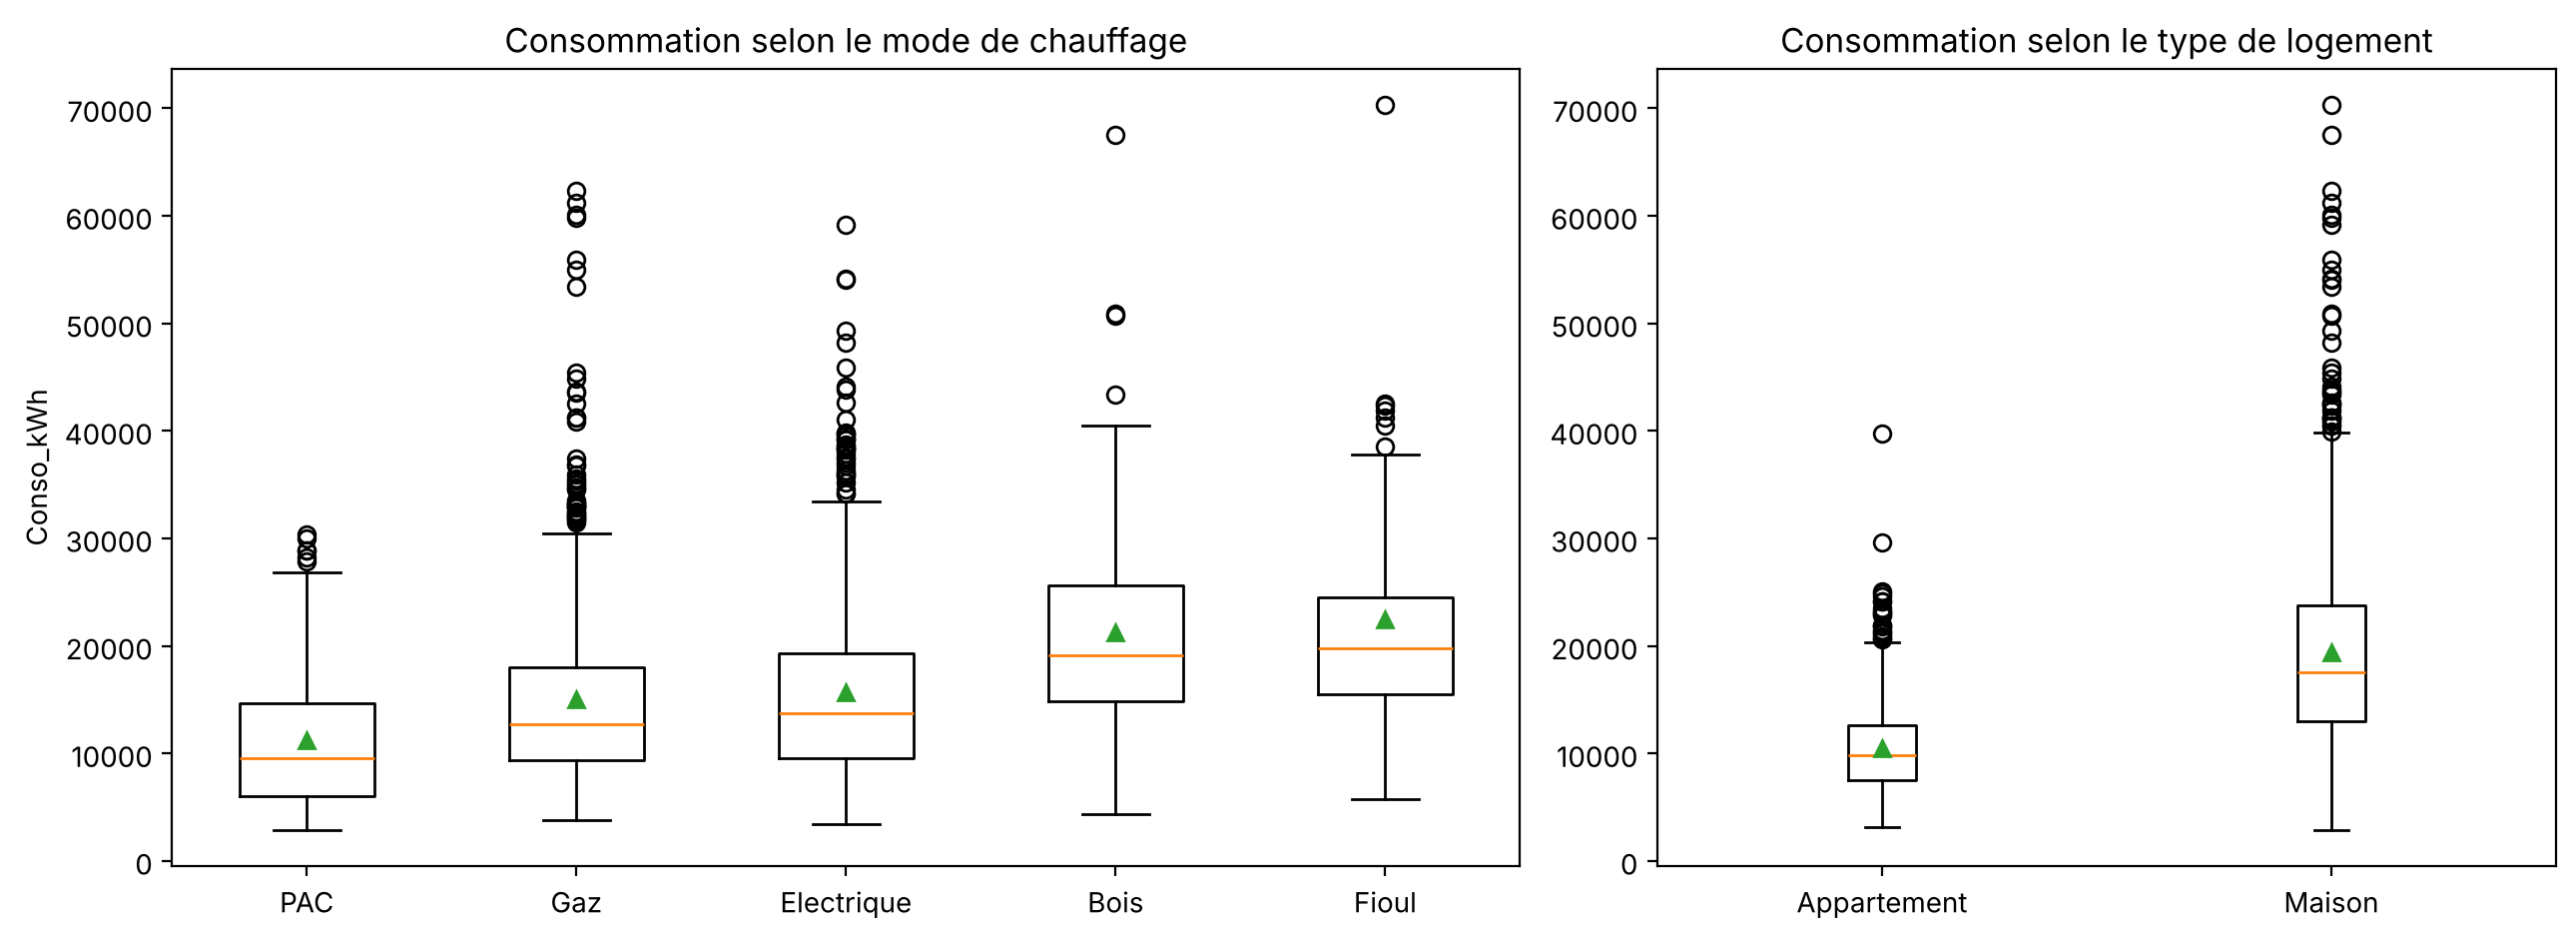

,count,mean,median,std
Chauffage,,,,
PAC,219,11216.0,9603.0,6339.0
Gaz,801,15021.0,12708.0,8401.0
Electrique,796,15682.0,13710.0,8450.0
Bois,130,21298.0,19098.0,9734.0
Fioul,52,22509.0,19786.0,11728.0


,count,mean,median,std
Maison,,,,
Appartement,875,10476.0,9813.0,4139.0
Maison,1123,19361.0,17531.0,9373.0


In [6]:
ordre = df.groupby("Chauffage")["Conso_kWh"].median().sort_values().index.tolist()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [3, 2]})
ax[0].boxplot([df.loc[df["Chauffage"] == c, "Conso_kWh"] for c in ordre], tick_labels=ordre, showmeans=True)
ax[0].set_title("Consommation selon le mode de chauffage"); ax[0].set_ylabel("Conso_kWh")
lab = {0: "Appartement", 1: "Maison"}
ax[1].boxplot([df.loc[df["Maison"] == m, "Conso_kWh"] for m in (0, 1)], tick_labels=[lab[0], lab[1]], showmeans=True)
ax[1].set_title("Consommation selon le type de logement")
plt.tight_layout(); plt.savefig(FIG / "a3_boxplots_chauffage_type.png", dpi=150); plt.show()

par_chauffage = df.groupby("Chauffage")["Conso_kWh"].agg(["count", "mean", "median", "std"]).loc[ordre].round(0)
par_type = df.groupby(df["Maison"].map(lab))["Conso_kWh"].agg(["count", "mean", "median", "std"]).round(0)
par_chauffage.to_csv(TAB / "a3_conso_par_chauffage.csv"); par_type.to_csv(TAB / "a3_conso_par_type.csv")
display(par_chauffage); display(par_type)

**Lecture.**

- **Chauffage** : la pompe à chaleur (PAC) consomme le moins (médiane ≈ 9 603 kWh, moyenne 11 216), le gaz et l'électrique sont proches (médianes ≈ 12 708 et 13 710), le bois (≈ 19 098) et surtout le fioul (≈ 19 786, moyenne 22 509) consomment le plus. Le fioul est rare (52 logements) : ses estimations seront moins précises.
- **Type de logement** : une maison consomme en moyenne **19 361 kWh** contre **10 476 kWh** pour un appartement, et la dispersion est plus de deux fois plus grande (écart-type 9 373 contre 4 139). Les boîtes des groupes ont des hauteurs très différentes, ce qui suggère de l'**hétéroscédasticité** (§5 de l'énoncé).
- Ces écarts bruts ne sont pas des effets causaux : maison et chauffage sont liés à la surface et au climat. Les modèles multivariés (§2) les contrôleront.

## 5. Quelles variables pourraient nécessiter une transformation logarithmique ?

**Critères.** Une variable est candidate au logarithme si (i) elle est **strictement positive**, (ii) elle est **asymétrique à droite** avec une queue épaisse, et (iii) une relation **multiplicative** ou en **pourcentage** est plausible (élasticité). On compare l'asymétrie et le kurtosis avant / après transformation.

In [7]:
candidates = ["Conso_kWh", "Surface_m2", "Revenu_kEUR", "DJU", "Age_referent", "Annee_construction", "Nb_occupants",
              "Nb_ecrans", "Teletravail_jours", "Artisans_RGE"]
rows = []
for c in candidates:
    x = df[c]
    ok = bool((x > 0).all())
    ligne = {"variable": c, "min": x.min(), "strict. positive": ok, "asym. niveau": stats.skew(x), "kurt. niveau": stats.kurtosis(x, fisher=False)}
    if ok:
        lx = np.log(x)
        ligne.update({"asym. log": stats.skew(lx), "kurt. log": stats.kurtosis(lx, fisher=False)})
    rows.append(ligne)
log_diag = pd.DataFrame(rows).set_index("variable").round(2)
log_diag.to_csv(TAB / "a3_diagnostic_logarithme.csv")
log_diag

,min,strict. positive,asym. niveau,kurt. niveau,asym. log,kurt. log
variable,,,,,,
Conso_kWh,2901.0,True,1.70,7.41,0.09,2.81
Surface_m2,15.0,True,0.88,4.11,-0.26,2.77
Revenu_kEUR,9.0,True,1.78,8.78,0.10,3.04
DJU,1300.0,True,0.07,3.14,-0.42,3.50
Age_referent,22.0,True,0.08,2.60,-0.65,3.08
Annee_construction,1880.0,True,-0.71,2.66,-0.74,2.71
Nb_occupants,1.0,True,0.37,2.84,-0.71,2.92
Nb_ecrans,0.0,False,0.69,3.43,NaN,NaN
Teletravail_jours,0.0,False,1.68,4.40,NaN,NaN


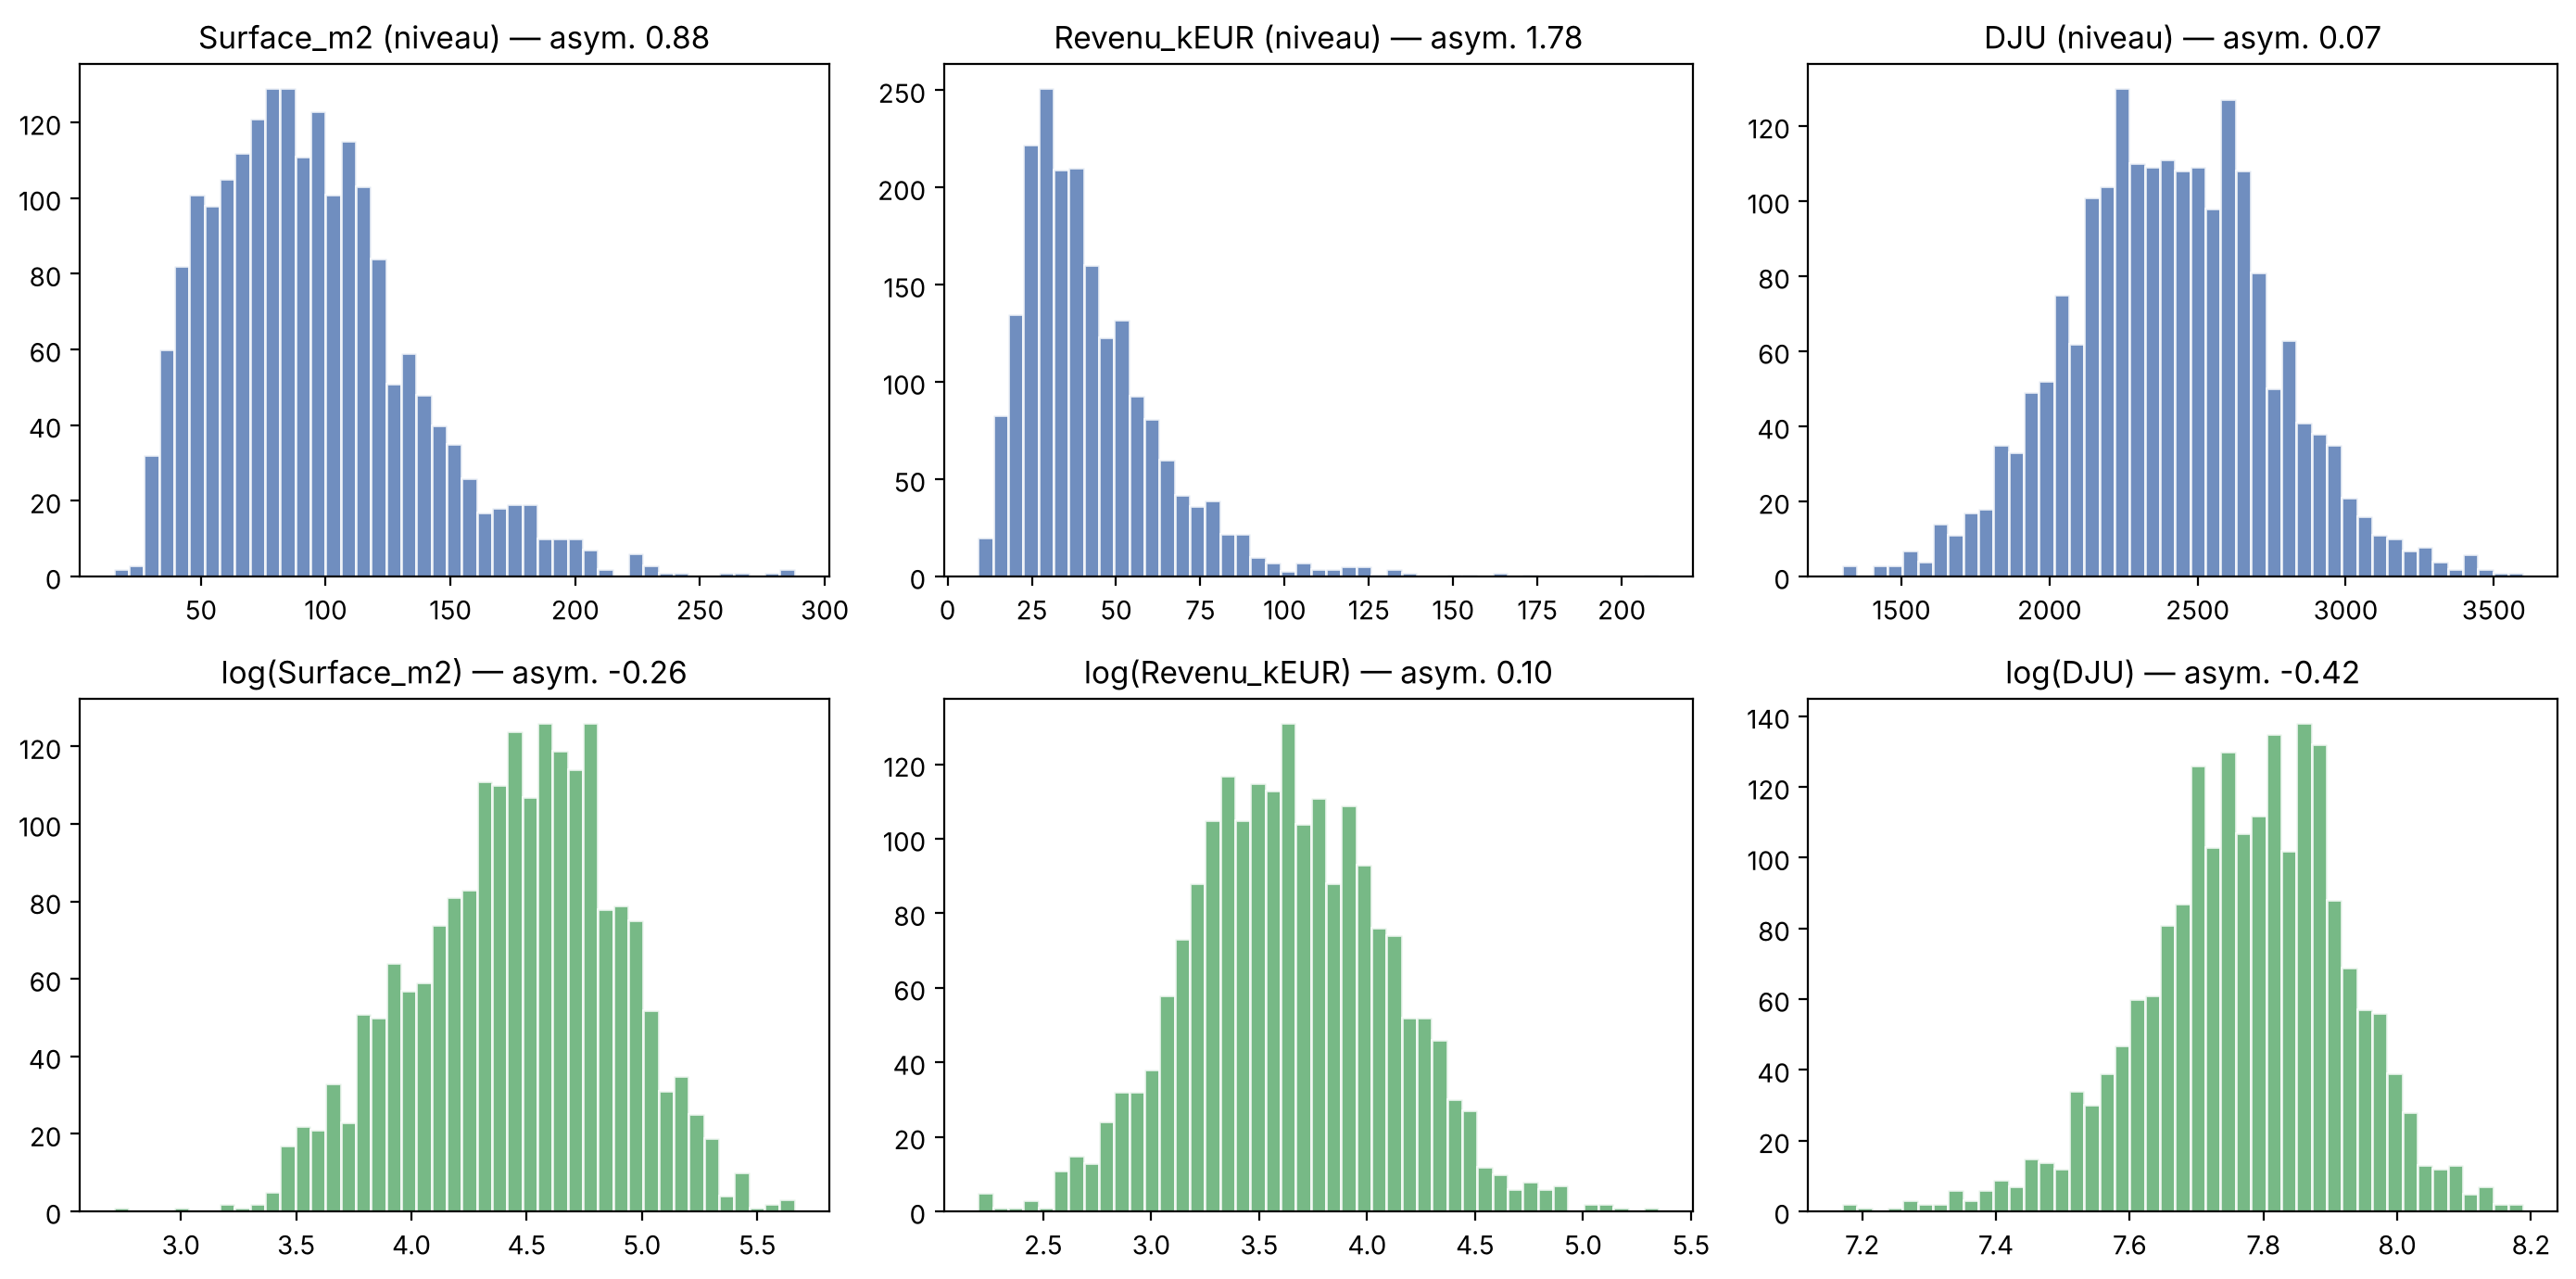

In [8]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for j, c in enumerate(["Surface_m2", "Revenu_kEUR", "DJU"]):
    ax[0, j].hist(df[c], bins=45, color="#4C72B0", alpha=.8, edgecolor="white"); ax[0, j].set_title(f"{c} (niveau) — asym. {stats.skew(df[c]):.2f}")
    ax[1, j].hist(np.log(df[c]), bins=45, color="#55A868", alpha=.8, edgecolor="white"); ax[1, j].set_title(f"log({c}) — asym. {stats.skew(np.log(df[c])):.2f}")
plt.tight_layout(); plt.savefig(FIG / "a3_log_candidats.png", dpi=150); plt.show()

**Conclusion.**

| Variable | Asymétrie (niveau) | Décision | Justification |
|---|---|---|---|
| `Conso_kWh` | 1,70 (kurtosis 7,41) | **Log** | Très asymétrique ; log ≈ normal (asym. 0,09, kurt. 2,81) |
| `Revenu_kEUR` | 1,78 (kurtosis 8,78) | **Log** | Queue de droite épaisse ; log symétrique (asym. 0,10) ; élasticité revenu naturelle |
| `Surface_m2` | 0,88 (kurtosis 4,11) | **Log** | Asymétrie modérée ; log symétrique (asym. −0,26) ; élasticité à la surface (énoncé §2.3) |
| `DJU` | 0,07 | **Log possible** | Déjà symétrique ; le log sert pour l'élasticité au climat (énoncé §2.3), non pour la forme de la loi |
| `Age_referent`, `Annee_construction`, `Artisans_RGE` | ≈ 0 ou négative | Niveau | Symétriques ; l'année de construction sera traitée par période (§2.4) |
| `Nb_occupants`, `Nb_ecrans`, `Teletravail_jours` | comptages | Niveau | Petits entiers ; `Teletravail_jours` vaut 0 pour 72 % des ménages, le log n'est pas défini |

Cette sélection correspond à la spécification **log-log** demandée en §2.3 (`log Conso` sur `log Surface`, `log DJU`, `log Revenu`).

## 6. Synthèse pour le rapport (partie 1.2)

- Échantillon : 1 998 logements ; consommation moyenne 15 470 kWh/an, médiane 13 441, écart-type 8 735.
- `Conso_kWh` est très asymétrique à droite (1,70) avec des queues épaisses (7,41) ; `log(Conso_kWh)` est quasi normale (0,09 ; 2,81 ; Jarque-Bera p = 0,062).
- Les maisons consomment presque deux fois plus que les appartements ; la PAC consomme le moins, le fioul et le bois le plus.
- Transformations logarithmiques retenues : `Conso_kWh`, `Surface_m2`, `Revenu_kEUR` (asymétrie) et `DJU` (élasticité au climat).
- Tableaux : `outputs/tables/a3_*.csv` ; figures : `outputs/figures/a3_*.png`.